# Buscando la gira con Simulated Annealing
Inteligencia Artificial - Facundo A. Lucianna - CEIA - FIUBA

En la notebook anterior vimos que gradiente descendente encuentra giras sin cruces, pero se queda atrapado en el primer mínimo local que encuentra. Cada ejecución termina en una gira distinta, y en la Gira Pueblo por Pueblo la diferencia entre la mejor y la peor es de cientos de km. Aun así, el manager ya mandó a imprimir los carteles con la mejor gira que encontramos, de casi 15.000 km.

Ahora vamos a usar **Simulated Annealing**. La idea es que el algoritmo, en general, se mueva hacia giras de menor costo, pero que de vez en cuando acepte moverse a una gira peor. De esta forma puede salir de un mínimo local, con la esperanza de llegar después a uno mejor.

Volvemos a empezar con la Gira Federal:

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np

import gira

random.seed(42)

capitals = gira.load_cities("capitales")
distances = gira.distance_matrix(capitals)

---
## La temperatura

El nombre del algoritmo viene del recocido (*annealing*) de los metales: un metal se calienta y después se enfría lentamente, para que sus átomos tengan tiempo de acomodarse en una estructura de baja energía. Si se enfría de golpe, los átomos quedan trabados en una estructura desordenada.

El algoritmo imita este proceso con un parámetro que llamamos **temperatura**. En cada iteración elegimos un vecino al azar y calculamos cuánto cambia el costo, $\Delta$:

- Si $\Delta < 0$, el vecino es mejor y nos movemos.
- Si $\Delta \ge 0$, el vecino es peor, pero igual nos movemos con probabilidad $e^{-\Delta / T}$, donde $T$ es la temperatura.

Esta fórmula viene de la distribución de Boltzmann. Como en nuestro problema el costo se mide en km, la temperatura también se mide en km. Veamos qué probabilidad de aceptar una gira peor tenemos para distintas temperaturas:

In [2]:
print("Probabilidad de aceptar una gira que es:")
print("                  10 km peor   100 km peor   1.000 km peor")
for temperature in [500, 50, 5]:
    probabilities = [math.exp(-delta / temperature) for delta in [10, 100, 1000]]
    print(
        f"T = {temperature:>3} km:     "
        + "      ".join(f"{probability:8.1%}" for probability in probabilities)
    )

Probabilidad de aceptar una gira que es:
                  10 km peor   100 km peor   1.000 km peor
T = 500 km:        98.0%         81.9%         13.5%
T =  50 km:        81.9%         13.5%          0.0%
T =   5 km:        13.5%          0.0%          0.0%


Con la temperatura alta, el algoritmo acepta casi cualquier cosa y se mueve por todo el espacio de búsqueda. Con la temperatura baja, prácticamente solo acepta mejoras y se comporta como gradiente descendente. La clave está en arrancar con una temperatura alta e ir enfriando de a poco.

En nuestra implementación la temperatura se multiplica en cada iteración por un número un poco menor que 1, al que llamamos `cooling_rate`. Para que sea más fácil de usar, en vez de pedir directamente `cooling_rate`, pedimos la temperatura inicial, la temperatura final y la cantidad de iteraciones, y calculamos `cooling_rate` para que la temperatura llegue a la final justo en la última iteración.

---
## Implementando Simulated Annealing

Veamos la implementación, prestando atención a los comentarios. Algunas diferencias con gradiente descendente:

- No miramos todos los vecinos: en cada iteración elegimos un único movimiento 2-opt al azar con `random_move()`.
- Como el algoritmo puede moverse a giras peores, la última gira no es necesariamente la mejor que visitó. Por eso guardamos aparte la mejor gira encontrada.
- Guardamos un historial cada 100 iteraciones, para después graficar cómo evoluciona la búsqueda.

In [3]:
# Cada cuántas iteraciones se guarda el historial
HISTORY_EVERY = 100


def simulated_annealing(
    tour,
    distances,
    initial_temperature=500,
    final_temperature=1,
    max_iterations=100_000,
):
    """
    Busca la mejor gira con Simulated Annealing. En cada iteración se elige un vecino
    al azar: si mejora la gira, se acepta; si la empeora en delta km, se acepta con
    probabilidad exp(-delta / temperatura). La temperatura baja de forma geométrica
    desde initial_temperature hasta final_temperature.

    Args:
        tour (list): Gira desde donde arranca la búsqueda.
        distances (np.ndarray): Matriz de distancias entre ciudades.
        initial_temperature (float, opcional): Temperatura inicial, en km. Por
                                               defecto 500.
        final_temperature (float, opcional): Temperatura en la última iteración, en
                                             km. Por defecto 1.
        max_iterations (int, opcional): Cantidad de iteraciones. Por defecto 100.000.

    Returns:
        tuple: (la mejor gira encontrada, diccionario con el historial: el costo de
               la gira actual, el de la mejor gira y la temperatura, cada
               HISTORY_EVERY iteraciones)
    """
    # La temperatura se multiplica por cooling_rate en cada iteración, de forma que
    # llegue a final_temperature en la última
    cooling_rate = (final_temperature / initial_temperature) ** (1 / max_iterations)
    temperature = initial_temperature

    cost = gira.cost_function(tour, distances)
    best_tour, best_cost = tour, cost
    history = {"cost": [], "best_cost": [], "temperature": []}

    for iteration in range(max_iterations):
        # Elegimos un vecino al azar y calculamos cuánto cambia el costo
        i, j = gira.random_move(len(tour))
        delta = gira.delta_cost(tour, i, j, distances)

        # Si mejora, lo aceptamos. Si empeora, lo aceptamos con probabilidad
        # exp(-delta / temperature)
        if delta < 0 or random.random() < math.exp(-delta / temperature):
            tour = gira.two_opt(tour, i, j)
            cost += delta
            if cost < best_cost:
                best_tour, best_cost = tour, cost

        if iteration % HISTORY_EVERY == 0:
            history["cost"].append(cost)
            history["best_cost"].append(best_cost)
            history["temperature"].append(temperature)

        temperature *= cooling_rate

    return best_tour, history

Arrancamos desde una gira al azar:

In [4]:
initial_tour = gira.init_state(capitals)
best_tour, history = simulated_annealing(initial_tour, distances)

print(
    "Costo de la gira inicial:",
    gira.format_km(gira.cost_function(initial_tour, distances)),
)
print(
    "Costo de la mejor gira:  ",
    gira.format_km(gira.cost_function(best_tour, distances)),
)

Costo de la gira inicial: 31.659 km
Costo de la mejor gira:   8.402 km


Veamos cómo evolucionó la búsqueda. Arriba graficamos el costo de la gira actual y el de la mejor gira encontrada hasta el momento, y abajo la temperatura:

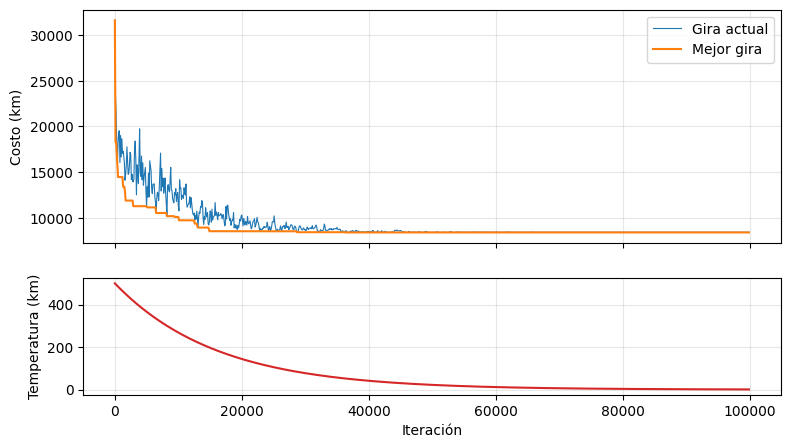

In [5]:
iterations = np.arange(len(history["cost"])) * HISTORY_EVERY

fig, (ax_cost, ax_temperature) = plt.subplots(
    2, 1, figsize=(9, 5), sharex=True, height_ratios=(2, 1)
)
ax_cost.plot(iterations, history["cost"], linewidth=0.8, label="Gira actual")
ax_cost.plot(iterations, history["best_cost"], label="Mejor gira")
ax_cost.set_ylabel("Costo (km)")
ax_cost.legend()
ax_cost.grid(alpha=0.3)

ax_temperature.plot(iterations, history["temperature"], color="tab:red")
ax_temperature.set_ylabel("Temperatura (km)")
ax_temperature.set_xlabel("Iteración")
ax_temperature.grid(alpha=0.3)
plt.show()

Al principio, con la temperatura alta, el costo de la gira actual sube y baja todo el tiempo: el algoritmo acepta muchos movimientos que empeoran la gira y recorre el espacio de búsqueda casi sin rumbo. A medida que la temperatura baja, acepta cada vez menos movimientos malos, el costo se estabiliza y al final el algoritmo se comporta como gradiente descendente, ajustando los últimos detalles.

Veamos la mejor gira que encontró:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tour(
    capitals, best_tour, distances, title="Simulated Annealing", interactive=True
)

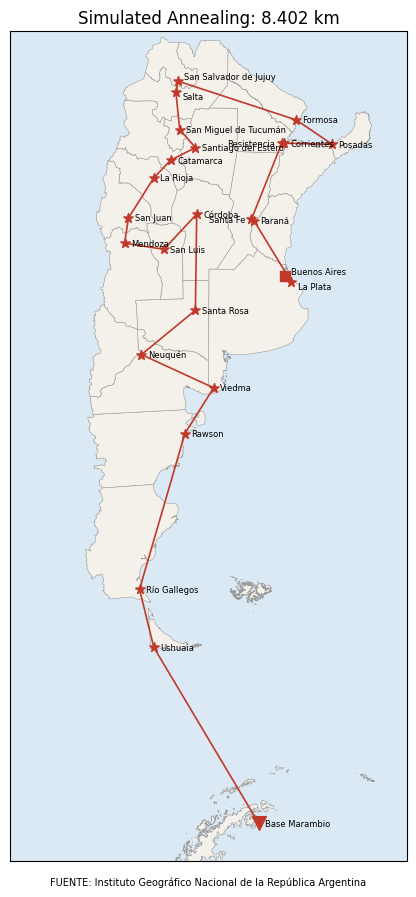

In [6]:
gira.plot_tour(capitals, best_tour, distances, title="Simulated Annealing")

---
## Comparando con gradiente descendente

Ejecutemos los dos algoritmos 20 veces, desde las mismas giras iniciales. Para gradiente descendente usamos la función de la notebook anterior, que está en `search_methods.py`:

In [7]:
from search_methods import gradient_descent

initial_tours = [gira.init_state(capitals) for _ in range(20)]

gradient_costs = []
annealing_costs = []
for tour in initial_tours:
    gradient_tour, _ = gradient_descent(tour, distances)
    gradient_costs.append(gira.cost_function(gradient_tour, distances))
    annealing_tour, _ = simulated_annealing(tour, distances)
    annealing_costs.append(gira.cost_function(annealing_tour, distances))

best_cost = min(gradient_costs + annealing_costs)
for name, costs in [
    ("Gradiente descendente", gradient_costs),
    ("Simulated Annealing", annealing_costs),
]:
    found_best = sum(np.isclose(costs, best_cost))
    print(name)
    print(f"    Mejor: {gira.format_km(min(costs))}")
    print(f"    Promedio: {gira.format_km(np.mean(costs))}")
    print(f"    Peor: {gira.format_km(max(costs))}")
    print(
        f"    Veces que encontró la gira de {gira.format_km(best_cost)}: {found_best}"
    )

Gradiente descendente
    Mejor: 8.402 km
    Promedio: 8.510 km
    Peor: 8.893 km
    Veces que encontró la gira de 8.402 km: 1
Simulated Annealing
    Mejor: 8.402 km
    Promedio: 8.406 km
    Peor: 8.450 km
    Veces que encontró la gira de 8.402 km: 16


Simulated Annealing encuentra la mejor gira de todas en la gran mayoría de las ejecuciones, y cuando no la encuentra queda muy cerca. Gradiente descendente, en cambio, depende mucho de la suerte de la gira inicial. No podemos asegurar que esa gira sea el óptimo, pero ningún algoritmo encontró una mejor.

La diferencia tiene un costo: cada ejecución de Simulated Annealing hace 100.000 iteraciones, mientras que gradiente descendente se detiene después de unos 20 pasos (aunque en cada paso evalúa los 253 vecinos).

---
## ¿Qué pasa si enfriamos demasiado rápido?

La velocidad de enfriamiento es clave. Si bajamos la temperatura muy rápido, el algoritmo no tiene tiempo de explorar y termina atrapado en un mínimo local, como el metal que se enfría de golpe. Probemos con distintas cantidades de iteraciones, manteniendo la misma temperatura inicial y final:

In [8]:
for max_iterations in [1_000, 10_000, 100_000]:
    costs = []
    for tour in initial_tours:
        annealing_tour, _ = simulated_annealing(
            tour, distances, max_iterations=max_iterations
        )
        costs.append(gira.cost_function(annealing_tour, distances))
    print(
        f"{max_iterations:>7} iteraciones: "
        f"promedio {gira.format_km(np.mean(costs))}, "
        f"peor {gira.format_km(max(costs))}"
    )

   1000 iteraciones: promedio 8.678 km, peor 9.257 km


  10000 iteraciones: promedio 8.433 km, peor 8.528 km


 100000 iteraciones: promedio 8.405 km, peor 8.450 km


Con pocas iteraciones el resultado es peor incluso que gradiente descendente: el algoritmo pasa tan rápido por las temperaturas altas que solo da vueltas al azar, y cuando la temperatura baja ya no le quedan iteraciones para ordenar la gira.

Elegir la temperatura inicial, la final y la cantidad de iteraciones es parte del trabajo de usar Simulated Annealing, y depende de cada problema. Una regla práctica para la temperatura inicial es que sea del orden de lo que empeora un movimiento típico al principio de la búsqueda, para que el algoritmo acepte buena parte de ellos.

---
## La Gira Pueblo por Pueblo

Ahora sí, vamos con la gira grande. Con 111 lugares el espacio de búsqueda es mucho más grande, así que usamos 2.000.000 de iteraciones y una temperatura final más baja. Ejecutamos los dos algoritmos 10 veces desde las mismas giras iniciales.

In [9]:
cities = gira.load_cities("pueblo_por_pueblo")
city_distances = gira.distance_matrix(cities)

gradient_results = []
annealing_results = []
for _ in range(10):
    tour = gira.init_state(cities)

    gradient_tour, _ = gradient_descent(tour, city_distances)
    gradient_results.append(
        (gira.cost_function(gradient_tour, city_distances), gradient_tour)
    )

    annealing_tour, _ = simulated_annealing(
        tour, city_distances, final_temperature=0.5, max_iterations=2_000_000
    )
    annealing_results.append(
        (gira.cost_function(annealing_tour, city_distances), annealing_tour)
    )

gradient_results.sort(key=lambda result: result[0])
annealing_results.sort(key=lambda result: result[0])
for name, results in [
    ("Gradiente descendente", gradient_results),
    ("Simulated Annealing", annealing_results),
]:
    costs = [cost for cost, _ in results]
    print(name)
    print(f"    Mejor: {gira.format_km(min(costs))}")
    print(f"    Promedio: {gira.format_km(np.mean(costs))}")
    print(f"    Peor: {gira.format_km(max(costs))}")

Gradiente descendente
    Mejor: 14.579 km
    Promedio: 15.076 km
    Peor: 15.392 km
Simulated Annealing
    Mejor: 14.123 km
    Promedio: 14.256 km
    Peor: 14.452 km


Incluso la peor gira de Simulated Annealing es mejor que la mejor de gradiente descendente. Comparemos las mejores giras de cada algoritmo:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tours(
    cities,
    {
        "Gradiente descendente": gradient_results[0][1],
        "Simulated Annealing": annealing_results[0][1],
    },
    city_distances,
    interactive=True,
)

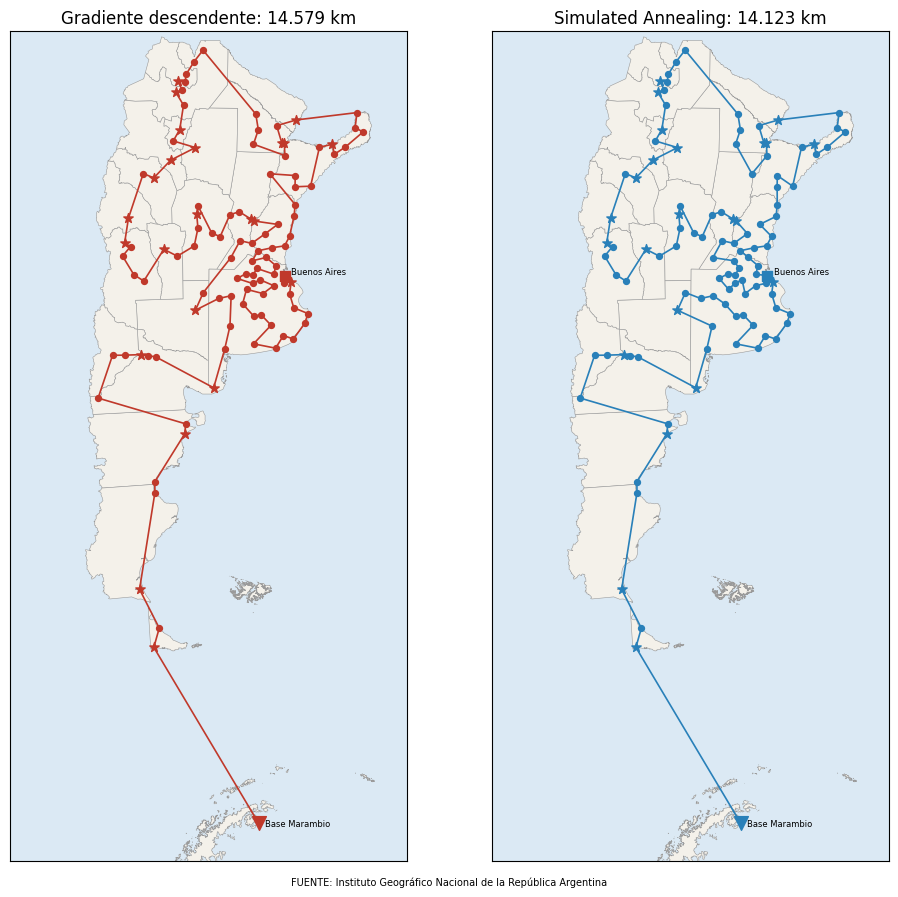

In [10]:
gira.plot_tours(
    cities,
    {
        "Gradiente descendente": gradient_results[0][1],
        "Simulated Annealing": annealing_results[0][1],
    },
    city_distances,
)

---
## Un nuevo cartel

La mejor gira de Simulated Annealing es bastante más corta que la del cartel que el manager mandó a imprimir. Con tantos km de avioneta de diferencia no queda otra: hay que tirar los carteles viejos e imprimir unos nuevos.

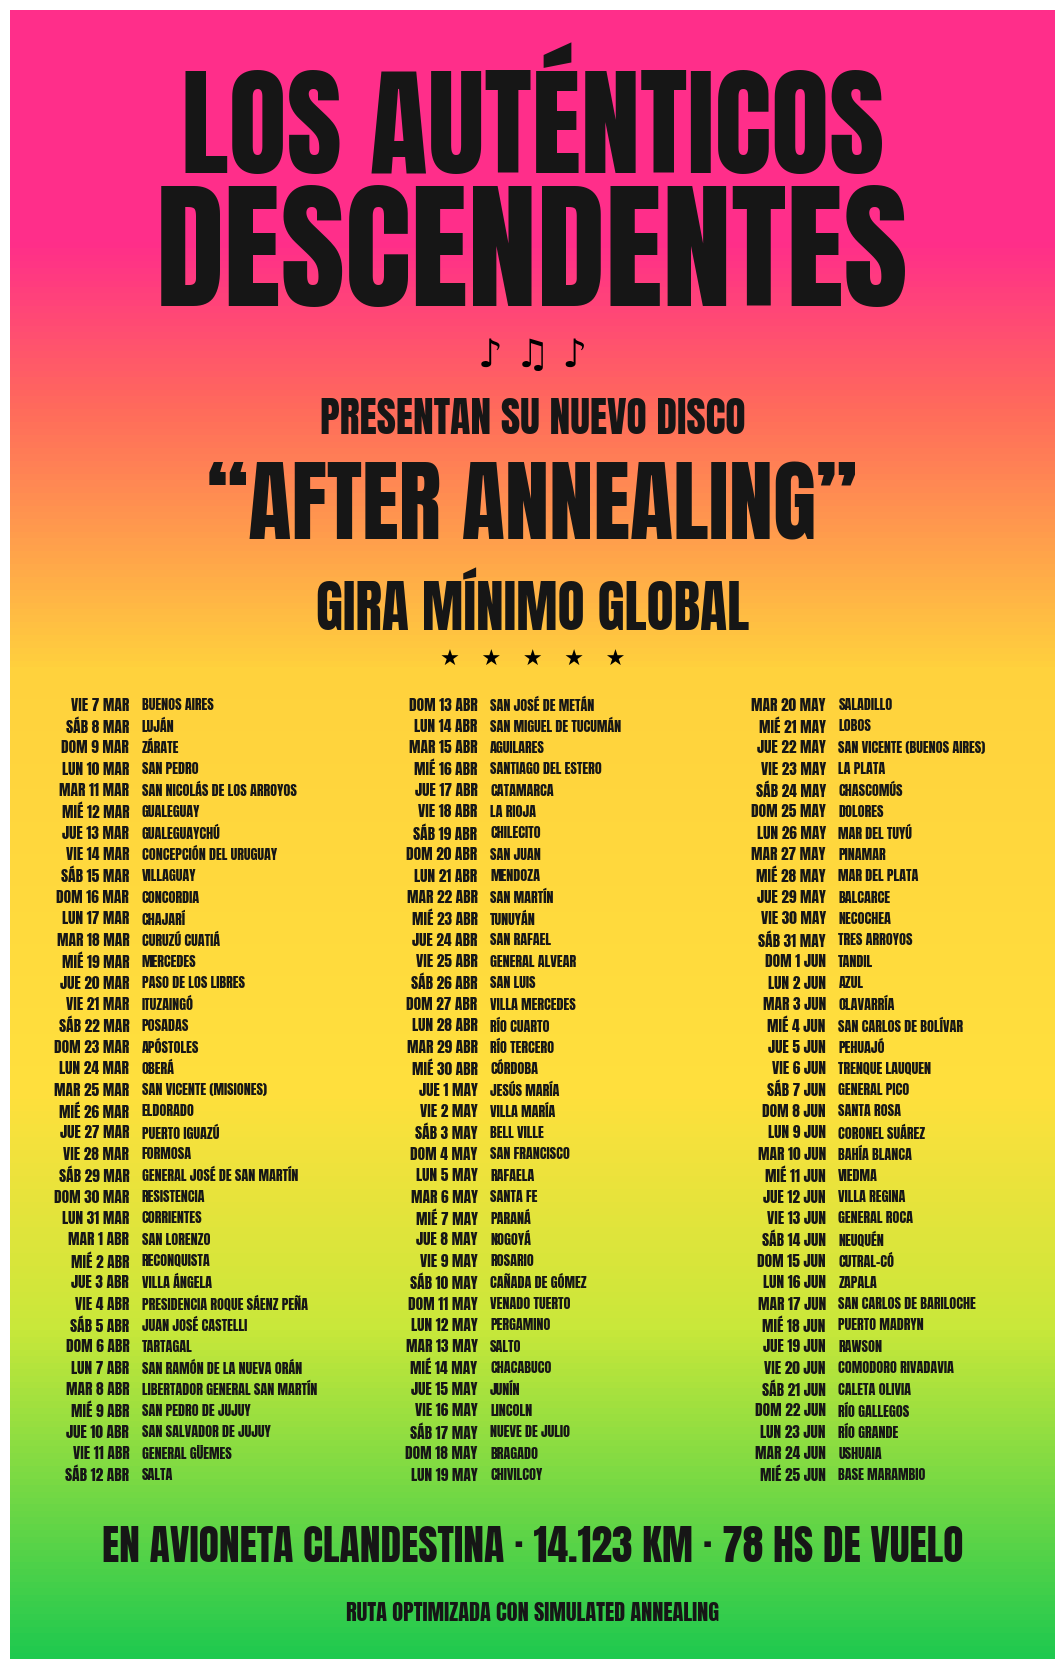

In [11]:
gira.plot_poster(
    cities,
    annealing_results[0][1],
    city_distances,
    footer="Ruta optimizada con Simulated Annealing",
)

Los carteles nuevos todavía están calientes cuando le contamos al manager que hay otro algoritmo que podemos probar: **Local Beam**, que en vez de seguir una única gira sigue varias a la vez. El manager respira hondo y nos pide que, esta vez, le avisemos antes de mandar a imprimir.

> 🧠 **Nota**: La función `simulated_annealing()` también está en el archivo `search_methods.py`, para poder usarla en las próximas notebooks.